In [3]:
import pandas as pd
import os

# 1. Setup - Adjust 'folder_path' to where your CSVs are stored
folder_path = r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2\Binary\SHAP"  # Path to your SHAP folder
top_n = 20              # Number of top genes to pick from each model

all_top_genes = []
model_genes_dict = {}

# 2. Iterate through all CSV files in the folder
csv_files = [f for f in os.listdir(folder_path) if f.endswith('.csv')]

for file in csv_files:
    file_path = os.path.join(folder_path, file)
    
    # Read the CSV
    df = pd.read_csv(file_path)
    
    # Sort by SHAP_Abs_Mean descending and take top N
    # Using 'Gene' as the column name based on your screenshot
    top_genes = df.sort_values(by='SHAP_Abs_Mean', ascending=False).head(top_n)['Gene'].tolist()
    
    model_genes_dict[file] = set(top_genes)
    all_top_genes.append(set(top_genes))

# 3. Find genes common to ALL models (Intersection)
common_genes = set.intersection(*all_top_genes)

# 4. Find genes that appear in at least X models (Consensus)
# This is often more useful if the intersection is too small
gene_counts = pd.Series([gene for sublist in all_top_genes for gene in sublist]).value_counts()

print(f"--- Analysis Results (Top {top_n} Genes) ---")
print(f"Total models analyzed: {len(csv_files)}")
print(f"Common genes in ALL models: {list(common_genes)}")
print("\n--- Top Genes by Frequency (Consensus) ---")
print(gene_counts[gene_counts > 1]) # Shows genes appearing in more than one model

--- Analysis Results (Top 20 Genes) ---
Total models analyzed: 6
Common genes in ALL models: []

--- Top Genes by Frequency (Consensus) ---
TSHZ2        5
CA1          5
MAOB         5
S100A8       5
GLYATL1P2    5
ITGB3BP      5
CRYM         4
WDR11-DT     4
IFITM3       4
IFI27        3
S100A12      3
FKBP5        3
ZNF385D      3
HSD17B3      3
TLN1         3
TEX9         3
ALAS2        3
KSR1         3
WFDC1        3
ITGA2B       3
MAGOHB       3
RGCC         3
DDIT4        3
RECQL        2
CNOT7        2
KALRN        2
CYB5R3       2
TC2N         2
ZNF542P      2
CAPNS1       2
Name: count, dtype: int64


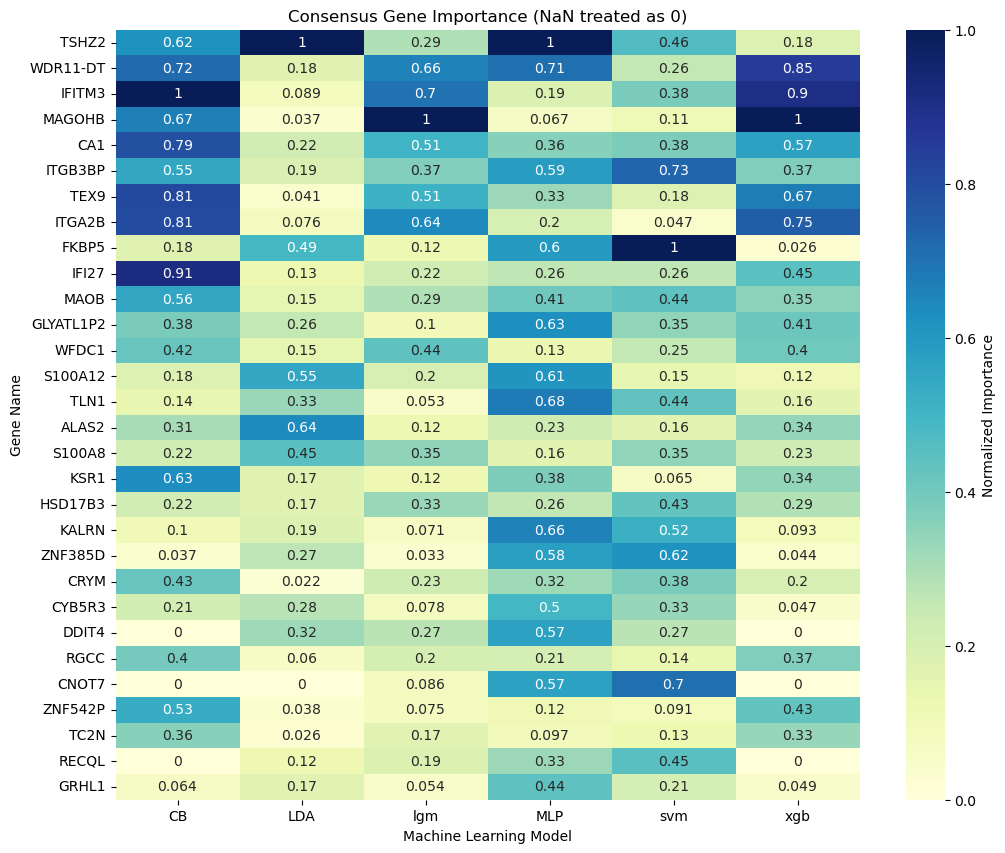

Top 10 Genes by Consensus (Fixed Logic):
          Consensus_Score
Gene                     
TSHZ2            0.592663
WDR11-DT         0.562221
IFITM3           0.543711
MAGOHB           0.480583
CA1              0.471256
ITGB3BP          0.466047
TEX9             0.424541
ITGA2B           0.420801
FKBP5            0.401279
IFI27            0.372186


In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os

# 1. Setup path and file list
folder_path = r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2\Binary\SHAP"
files = ['SHAP_CB.csv', 'SHAP_LDA.csv', 'SHAP_lgm.csv', 'SHAP_MLP.csv', 'SHAP_svm.csv', 'SHAP_xgb.csv']

# 2. Merge all files into one DataFrame
master_df = pd.DataFrame()

for file in files:
    model_name = file.replace('SHAP_', '').replace('.csv', '') 
    df = pd.read_csv(os.path.join(folder_path, file))
    
    temp_df = df[['Gene', 'SHAP_Abs_Mean']].copy()
    temp_df.columns = ['Gene', model_name]
    
    if master_df.empty:
        master_df = temp_df
    else:
        master_df = pd.merge(master_df, temp_df, on='Gene', how='outer')

master_df.set_index('Gene', inplace=True)

# --- THE KEY CHANGE ---
# Fill NaN with 0 BEFORE scaling. 
# This ensures that genes missing from a model are treated as having zero importance.
master_df.fillna(0, inplace=True)
# ---------------------

# 3. Scale the data (0 to 1) 
# Now that NaNs are 0, the .min() will correctly be 0 for most columns.
master_scaled = (master_df - master_df.min()) / (master_df.max() - master_df.min())

# 4. Calculate Consensus Score
# With 0s instead of NaNs, the mean will now correctly divide by 6 (the number of models)
master_scaled['Consensus_Score'] = master_scaled.mean(axis=1)
master_scaled = master_scaled.sort_values(by='Consensus_Score', ascending=False)

# 5. Visualize Top 30 Genes
plt.figure(figsize=(12, 10))
top_30 = master_scaled.head(30).drop(columns=['Consensus_Score'])
sns.heatmap(top_30, annot=True, cmap="YlGnBu", cbar_kws={'label': 'Normalized Importance'})
plt.title("Consensus Gene Importance (NaN treated as 0)")
plt.ylabel("Gene Name")
plt.xlabel("Machine Learning Model")
plt.show()

# 6. Show results
print("Top 10 Genes by Consensus (Fixed Logic):")
print(master_scaled[['Consensus_Score']].head(10))

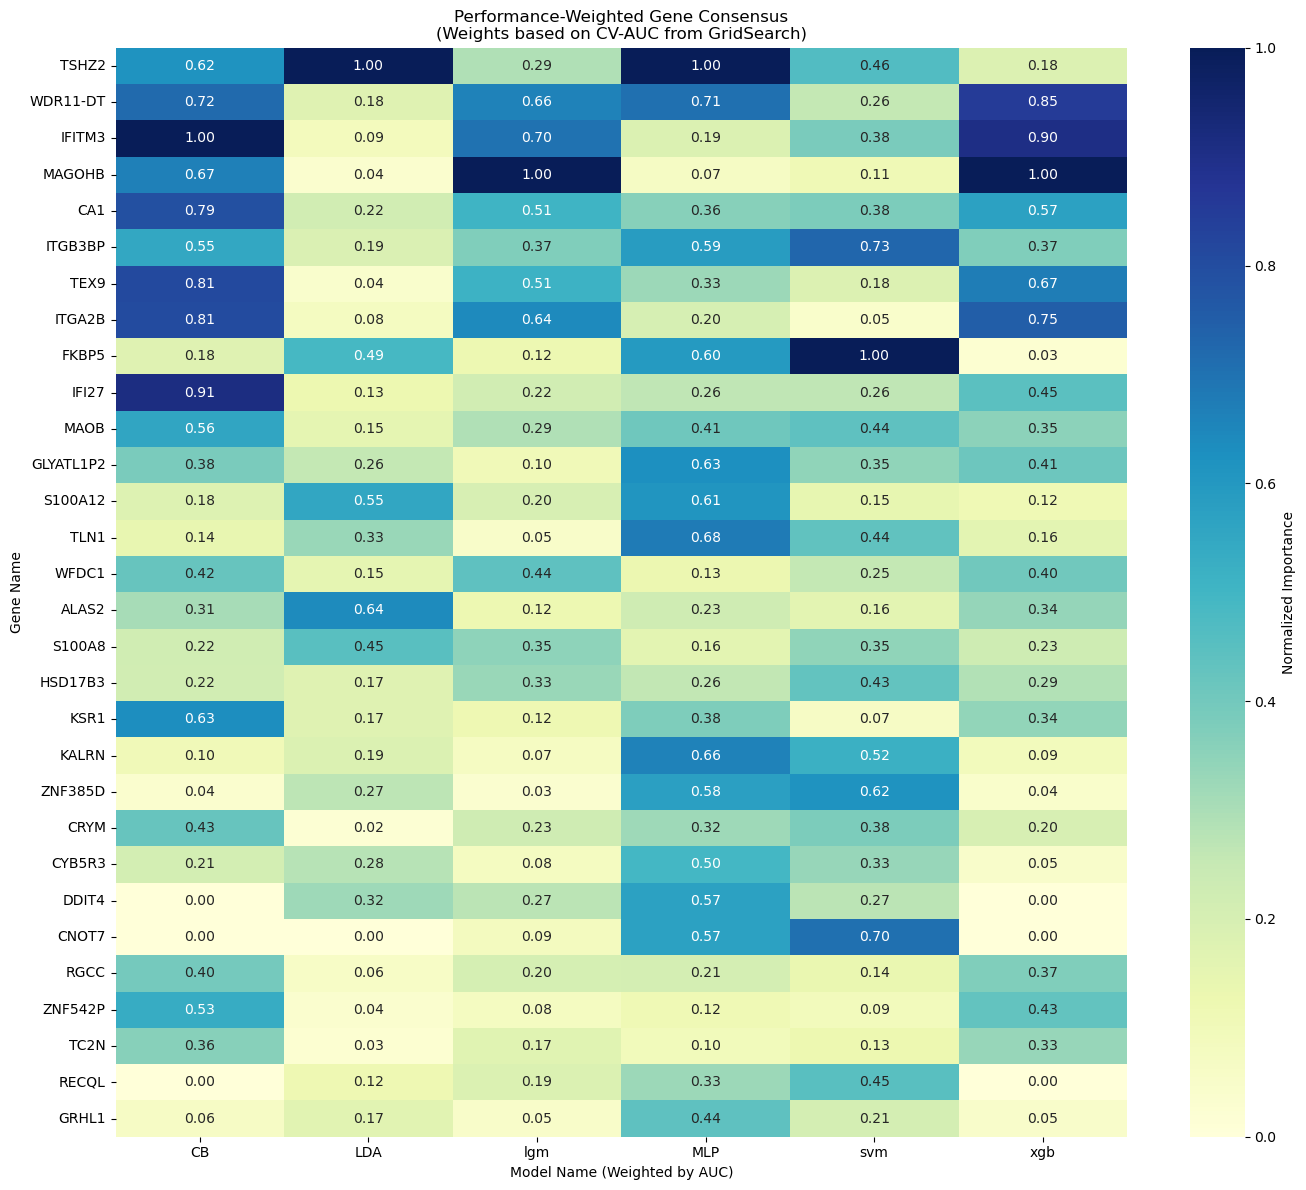

Top 10 Biomarkers saved to: C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2\Binary\SHAP\Consensus_Biomarkers_2026.csv
          Consensus_Score
Gene                     
TSHZ2            0.594386
WDR11-DT         0.560781
IFITM3           0.540958
MAGOHB           0.477167
CA1              0.470002
ITGB3BP          0.466696
TEX9             0.422513
ITGA2B           0.418079
FKBP5            0.404098
IFI27            0.370757


In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os
import numpy as np

# 1. Setup path and file list
folder_path = r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2\Binary\SHAP"
files = ['SHAP_CB.csv', 'SHAP_LDA.csv', 'SHAP_lgm.csv', 'SHAP_MLP.csv', 'SHAP_svm.csv', 'SHAP_xgb.csv']

# 2. Extract AUC Weights from your GridSearchCV results
# Note: best_idx helps grab the AUC from the exact parameter combo that won the 'BA' refit


weights = {
    'CB': 0.91816,
    'LDA': 0.93059,
    'lgm': 0.92221,
    'MLP': 0.93696,
    'svm': 0.93748,
    'xgb': 0.91681
}

# 3. Merge files
master_df = pd.DataFrame()
for file in files:
    model_name = file.replace('SHAP_', '').replace('.csv', '') 
    df = pd.read_csv(os.path.join(folder_path, file))
    
    temp_df = df[['Gene', 'SHAP_Abs_Mean']].copy()
    temp_df.columns = ['Gene', model_name]
    
    if master_df.empty:
        master_df = temp_df
    else:
        master_df = pd.merge(master_df, temp_df, on='Gene', how='outer')

master_df.set_index('Gene', inplace=True)

# 4. Methodology Fix: Treat missing genes as 0 importance
master_df.fillna(0, inplace=True)

# 5. Normalization (Min-Max Scaling 0-1)
master_scaled = (master_df - master_df.min()) / (master_df.max() - master_df.min())

# 6. Weighted SHAP Aggregation (The Paper Method)
weighted_sum = sum(master_scaled[m] * weights[m] for m in weights)
total_weight = sum(weights.values())
master_scaled['Consensus_Score'] = weighted_sum / total_weight

# 7. Sort and Filter for Top 30
master_scaled = master_scaled.sort_values(by='Consensus_Score', ascending=False)
top_30 = master_scaled.head(30).drop(columns=['Consensus_Score'])

# 8. Heatmap Visualization
plt.figure(figsize=(14, 12))
sns.heatmap(top_30, annot=True, fmt=".2f", cmap="YlGnBu", cbar_kws={'label': 'Normalized Importance'})

plt.title("Performance-Weighted Gene Consensus\n(Weights based on CV-AUC from GridSearch)")
plt.ylabel("Gene Name")
plt.xlabel("Model Name (Weighted by AUC)")
plt.tight_layout()
plt.show()

# 9. Save final Consensus Table for your Paper
output_path = os.path.join(folder_path, "Consensus_Biomarkers_2026.csv")
master_scaled[['Consensus_Score']].to_csv(output_path)
print(f"Top 10 Biomarkers saved to: {output_path}")
print(master_scaled[['Consensus_Score']].head(10))

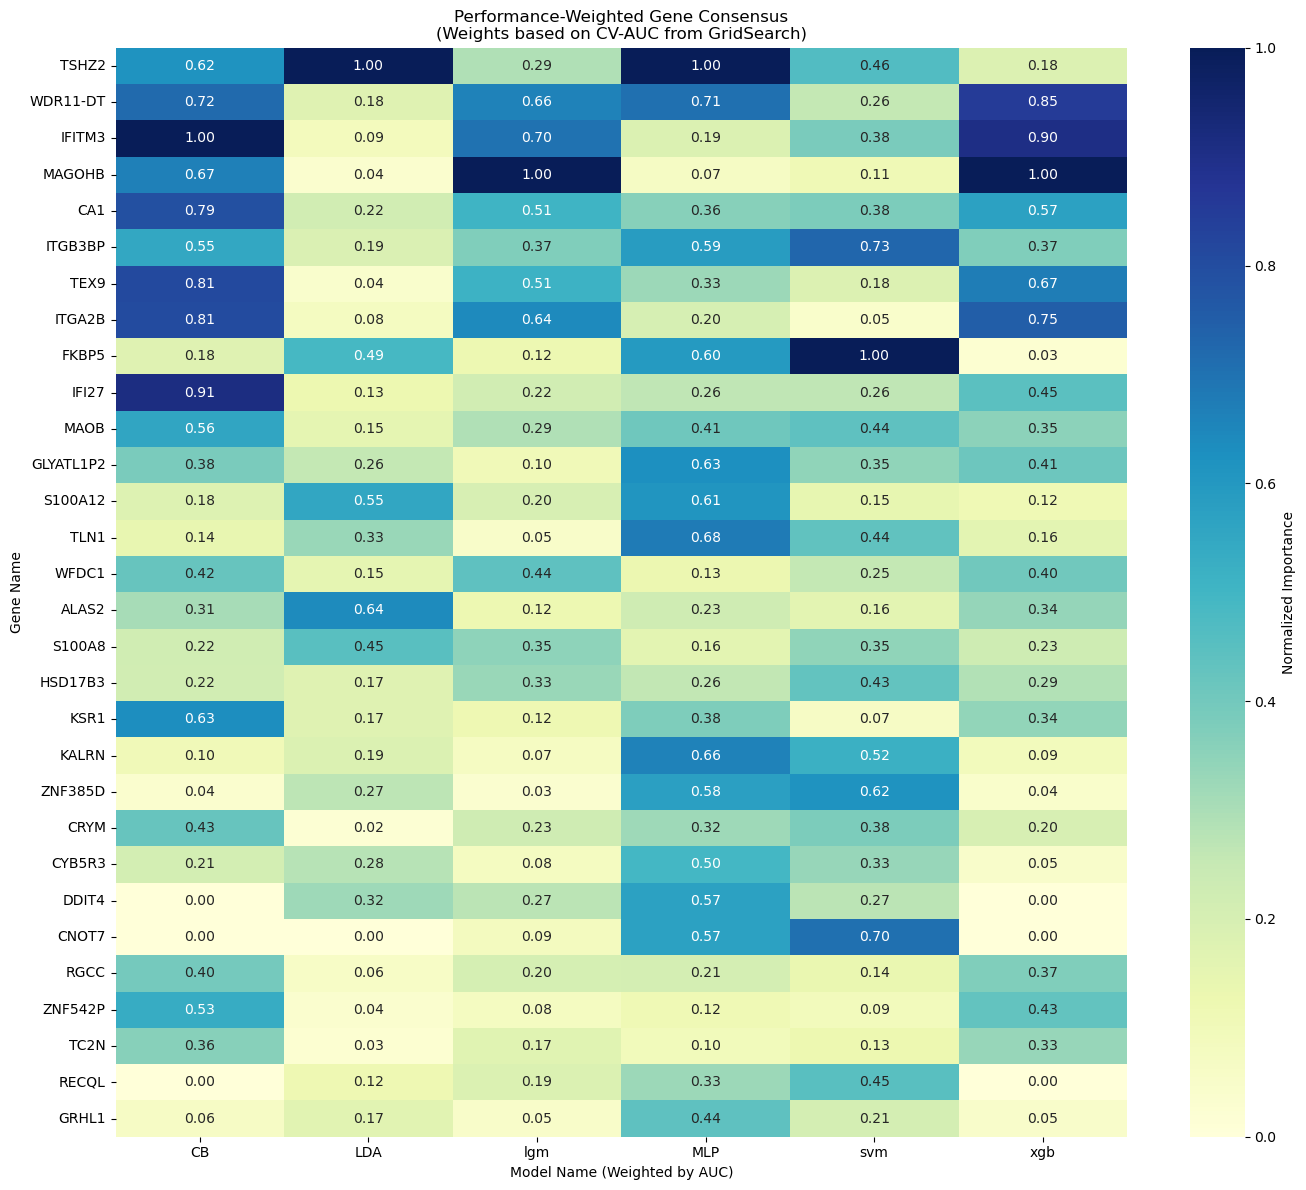

Heatmap saved to: C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2\Binary\SHAP\Consensus_Heatmap_2026.png


In [3]:
# 8. Heatmap Visualization
plt.figure(figsize=(14, 12))

sns.heatmap(
    top_30,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    cbar_kws={'label': 'Normalized Importance'}
)

plt.title("Performance-Weighted Gene Consensus\n(Weights based on CV-AUC from GridSearch)")
plt.ylabel("Gene Name")
plt.xlabel("Model Name (Weighted by AUC)")
plt.tight_layout()

# SAVE HEATMAP
heatmap_path = os.path.join(folder_path, "Consensus_Heatmap_2026.png")
plt.savefig(heatmap_path, dpi=300, bbox_inches='tight')

plt.show()

print(f"Heatmap saved to: {heatmap_path}")